In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from src.data import LABELS, SEED, load_dataset
from src import data
DATA_PATH = "data/ssh_attacks.parquet"

## Experiment 1

TODO: Verify Parquet schema, stable IDs, timestamps and Set_Fingerprint encoding; decode reference sets explicitly.

Record settings, observations and limitations after the experiment runs.

In [3]:
from src.data import load_dataset
try: 
    dF=load_dataset(DATA_PATH)
    display(dF.isna().sum()) #preferibile alla print quando si visualizzano dataframe e series mentre print è preferibile per messaggi brevi
    #btw mostra quanti campi per ogni colonna sono vuoti -> dai risultati nessuno
    rV=dF.isna().all(axis=1).sum()
    cV=dF.isna().all(axis=0).sum()
    print(f"ci sono {rV} righe completamente vuote e {cV} colonne completamente vuote")
except Exception:
    print("ci sono problemi capo")
    #a dF poi ci pensiamo per ora non serve perchè tutto funziona bene
finally:
    print ("nel bene o nel male abbiamo finito il caricamento del dataset")

#poi lo rendiamo più serio



session_id         0
full_session       0
first_timestamp    0
Set_Fingerprint    0
dtype: int64

ci sono 0 righe completamente vuote e 0 colonne completamente vuote
nel bene o nel male abbiamo finito il caricamento del dataset


In [21]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
"""aggiorniamo direttamente il data frame originale"""
dF["n_chars"] = dF["full_session"].str.len()
dF["n_tokens"] = dF["full_session"].map(data.tokenize_shell).map(len)
"""usiamo CountVectorizer che tokenizza e fa il conteggio delle occorrenze"""
vectorizer = CountVectorizer() #costruttore
tokens=vectorizer.fit_transform(dF["full_session"])
#così ho creato una matrice sparsa (si risparmia circa 99 volte la memoria in media con una matrice sparsa rispetto a quella densa no joke) ogni riga è una sessione nello stesso ordine di full_session ,mentre le colonne sono i token ogni cella dice quanti token per sessione
termini = vectorizer.get_feature_names_out()
#così estraggo una lista di token

riepilogo_tokens = pd.DataFrame({
    "termine": termini,
    "occorrenze": np.asarray(tokens.sum(axis=0)).ravel(),
    "sessioni": tokens.getnnz(axis=0),
}) #questo è per estrarre i common text elements
#in questo modo creo un dataframe con 3 colonne: 1 con tutti i token; 1 con quante occorrenze in generale; 1 con quante sessioni è spuntata
#sto dataframe serve solo per ordinare i risultati
display(riepilogo_tokens.nlargest(20, "occorrenze"))
mlb = MultiLabelBinarizer(classes=data.LABELS)
"""qui facciamo un salto diverso, non abbiamo più bisogno di vettorizzare ma andiamo di matrice binaria che indica semplicemente 0 1 tabella x sessione, 
noi necessitiamo di una matrice densa che otterremo solo post trasformazione, questo intanto è un obj"""
Y=mlb.fit_transform(dF["Set_Fingerprint"]) #otteniamo ogni riga una sessione nell'ordine della series, ogni colonna una label
for i in range (0, len(mlb.classes_)):
    print(f"etichetta {mlb.classes_[i]} presente in {Y[:,i].sum(axis=0)} sessioni")
lsz=Y.sum(axis=1)
#label set size ma non lo mostro perchè è troppo pesanti quando ne trarremo le conclusioni lo faremo 
cooccorrenze = pd.DataFrame(
    Y.T @ Y,
    index=mlb.classes_,
    columns=mlb.classes_,
)

display(cooccorrenze)
display(pd.Series(lsz).value_counts().sort_index())
#Distribuzione della label-set size



,termine,occorrenze,sessioni
239016,tmp,1434324,213798
54843,grep,1278495,213922
246356,var,1207437,213311
31232,cat,1082802,231385
42809,echo,975347,231596
217707,proc,656668,230931
243792,uname,639146,213131
107907,name,638991,213464
34653,cpuinfo,638869,213348
246357,var03522123,637129,212352


etichetta Persistence presente in 211295 sessioni
etichetta Discovery presente in 232145 sessioni
etichetta Defense Evasion presente in 18999 sessioni
etichetta Execution presente in 92927 sessioni
etichetta Impact presente in 27 sessioni
etichetta Other presente in 327 sessioni
etichetta Harmless presente in 2206 sessioni


,Persistence,Discovery,Defense Evasion,Execution,Impact,Other,Harmless
Persistence,211295,211281,622,91576,7,310,1950
Discovery,211281,232145,18825,92279,17,313,1968
Defense Evasion,622,18825,18999,1024,7,3,58
Execution,91576,92279,1024,92927,19,323,266
Impact,7,17,7,19,27,2,8
Other,310,313,3,323,2,327,14
Harmless,1950,1968,58,266,8,14,2206


1      2928
2    136458
3     92571
4      1025
5        50
6         2
7         1
Name: count, dtype: int64

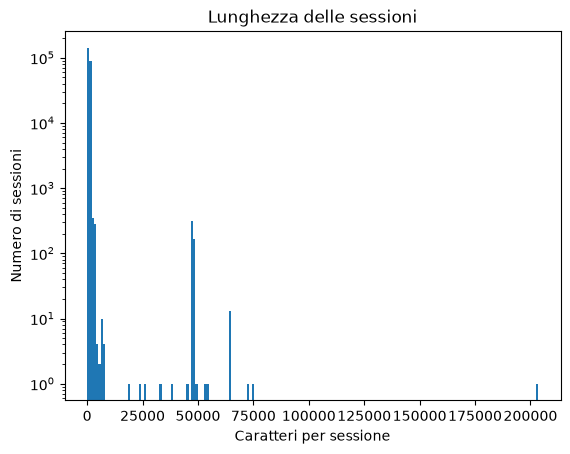

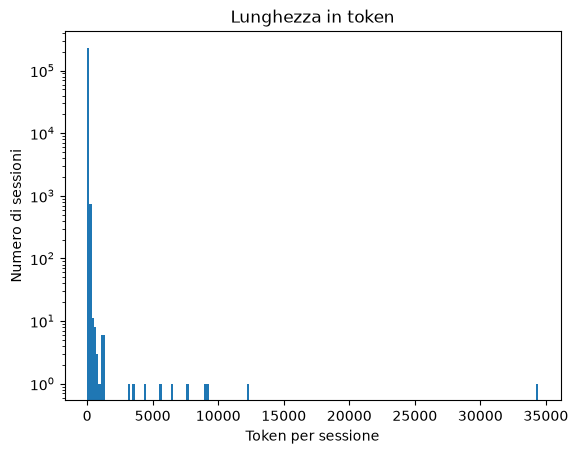

,n_chars,n_tokens
count,233035.000000,233035.000000
mean,1013.865119,120.801399
std,2282.583441,87.692157
min,3.000000,2.000000
50%,620.000000,116.000000
90%,1418.000000,138.000000
95%,1421.000000,138.000000
99%,1934.000000,161.000000
max,203442.000000,34404.000000


In [18]:
import matplotlib.pyplot as plt
caratteri = dF["n_chars"]
plt.hist(caratteri, bins=200, log=True)
plt.xlabel("Caratteri per sessione")
plt.ylabel("Numero di sessioni")
plt.title("Lunghezza delle sessioni")
plt.show()
#distribuzione del numero di caratteri per sessione
tok=dF["n_tokens"]
plt.hist(tok,bins=200,log=True)
plt.xlabel("Token per sessione")
plt.ylabel("Numero di sessioni")
plt.title("Lunghezza in token")
plt.show()
"""Quello lineare fa vedere quanto dominano le lunghezze più comuni. 
Quello logaritmico ti aiuta a vedere dove cadono le sessioni rare. 
La distribuzione dei dati è la stessa, ma i due grafici ne mettono in evidenza aspetti diversi."""
display(dF[["n_chars", "n_tokens"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

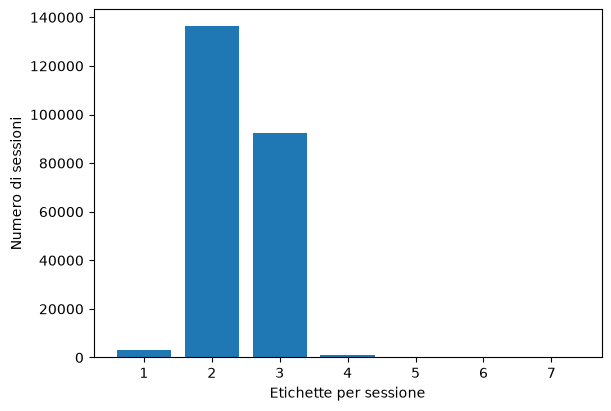

In [19]:
#quante sess hanno 1,2,3 etichette?
distribuzione = pd.Series(lsz).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.bar(distribuzione.index, distribuzione.values)
ax.set(xlabel="Etichette per sessione", ylabel="Numero di sessioni")
ax.set_xticks(distribuzione.index)

plt.show()

## Experiment 2

TODO: Measure character/token lengths, common text, label counts/co-occurrences and label-set sizes.

Record settings, observations and limitations after the experiment runs.

## Experiment 3

TODO: Plot sessions and label composition over time; define counted population and consider the November 2019 upgrade.

Record settings, observations and limitations after the experiment runs.

## Experiment 4

TODO: Define shell tokenizer rules; contrast ordinary text tokenization with shell examples.

Record settings, observations and limitations after the experiment runs.

## Experiment 5

TODO: Compare two representations including count/TF-IDF; justify normalization and consult teacher.

Record settings, observations and limitations after the experiment runs.

## Experiment 6

TODO: Inspect near-duplicate template groups and counterexamples without labels; hand groups/features to P2/P3.

Record settings, observations and limitations after the experiment runs.

## Results

TODO: insert measured tables/figures and their denominators. No results available yet.

## Interpretation and handoff

TODO: discuss limitations, uncertainty, reference agreement where relevant, and outputs needed by other developers. Update TODO.md with evidence.